In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df = pd.read_csv('secondary_data.csv', sep=';')

print('Исходный размер:', df.shape)
print('\nПервые 3 строки:')
df.head(3)

Исходный размер: (61069, 21)

Первые 3 строки:


,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,...,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
0,p,15.26,x,g,o,f,e,NaN,w,16.95,...,s,y,w,u,w,t,g,NaN,d,w
1,p,16.60,x,g,o,f,e,NaN,w,17.99,...,s,y,w,u,w,t,g,NaN,d,u
2,p,14.07,x,g,o,f,e,NaN,w,17.80,...,s,y,w,u,w,t,g,NaN,d,w


In [29]:
# Отбор колонок и пропуски
num_cols = ['cap-diameter', 'stem-height', 'stem-width']
cat_cols = ['cap-shape', 'cap-color', 'does-bruise-or-bleed', 'season']
target_col = 'class'

df = df[num_cols + cat_cols + [target_col]].copy()

print('Пропуски по колонкам:')
print(df.isnull().sum())

# Заполняем пропуски меткой 'missing'
for c in cat_cols:
  df[c] = df[c].fillna('missing')

# В числовых признаках берем медиану
for n in num_cols:
  df[n] = df[n].fillna(df[n].median())

# Переводим таргет в 0 и 1: 1 - poisonous, 0 - edible
df['target'] = (df['class'] == 'p').astype(int)
df = df.drop(columns=['class'])

print('\nБаланс классов:')
print(
    df['target'].value_counts(normalize=True).rename({1: 'poisonous', 0: 'edible'})
)

Пропуски по колонкам:
cap-diameter            0
stem-height             0
stem-width              0
cap-shape               0
cap-color               0
does-bruise-or-bleed    0
season                  0
class                   0
dtype: int64

Баланс классов:
target
poisonous    0.554913
edible       0.445087
Name: proportion, dtype: float64


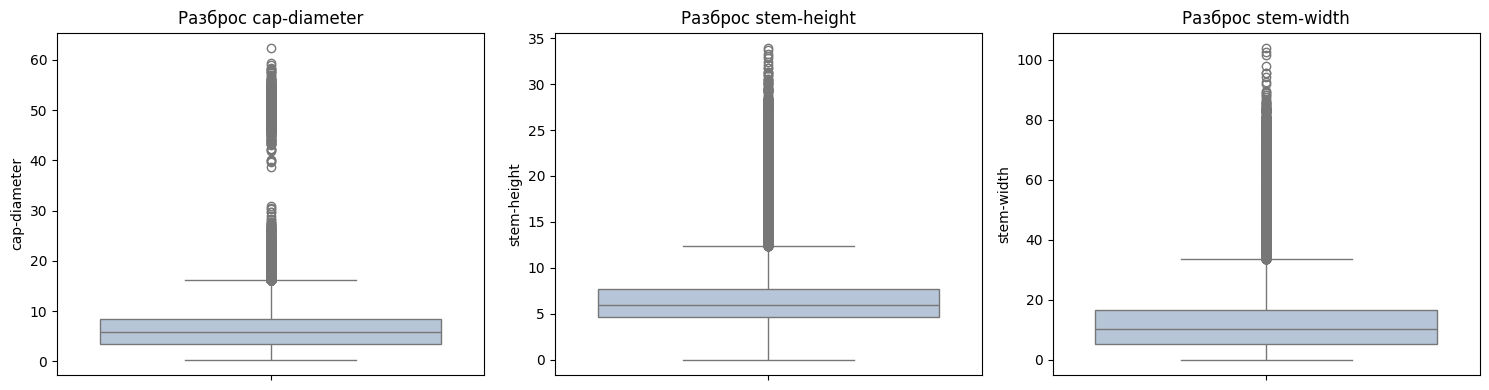

Осталось строк после фильтрации выбросов: 60156


In [30]:
# Первичный анализ и EDA
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(num_cols):
  sns.boxplot(y=df[col], ax=axes[i], color='lightsteelblue')
  axes[i].set_title(f'Разброс {col}')

plt.tight_layout()
plt.show()

# Мягко срезаем выбросы выше 99.5 процентиля
for col in num_cols:
  limit = df[col].quantile(0.995)
  df = df[df[col] <= limit]

print(f'Осталось строк после фильтрации выбросов: {len(df)}')

In [31]:
# Разделение на Train, Val и Test
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns=['target'])
y = df['target'].values

# 60% Train / 20% Val / 20% Test
X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(
    f'Train: {len(X_train_raw)}, Val: {len(X_val_raw)}, Test: {len(X_test_raw)}'
)

# Препроцессинг
scaler = StandardScaler()
ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')

X_train_num = scaler.fit_transform(X_train_raw[num_cols])
X_train_cat = ohe.fit_transform(X_train_raw[cat_cols])
X_train = np.hstack([X_train_num, X_train_cat])

X_val = np.hstack(
    [scaler.transform(X_val_raw[num_cols]), ohe.transform(X_val_raw[cat_cols])]
)

X_test = np.hstack([
    scaler.transform(X_test_raw[num_cols]),
    ohe.transform(X_test_raw[cat_cols]),
])

print('Итого фичей на вход модели:', X_train.shape[1])

Train: 36093, Val: 12031, Test: 12032
Итого фичей на вход модели: 24


In [32]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)

dummy_val_preds = dummy.predict(X_val)

print('--- Baseline на Val ---')
print(f'Accuracy: {accuracy_score(y_val, dummy_val_preds):.4f}')
print(f'F1-score: {f1_score(y_val, dummy_val_preds):.4f}')
print(f'ROC-AUC:  {roc_auc_score(y_val, dummy.predict_proba(X_val)[:, 1]):.4f}')

--- Baseline на Val ---
Accuracy: 0.5634
F1-score: 0.7207
ROC-AUC:  0.5000


In [33]:
# Обучение модели из Sklearn с подбором параметров
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# Сетка гиперпараметров дерева
param_grid = {'max_depth': [3, 5, 7, 10, 15], 'min_samples_split': [10, 50, 100]}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
)
grid.fit(X_train, y_train)

best_sk_tree = grid.best_estimator_
print('Лучшие параметры для Sklearn Tree:', grid.best_params_)

sk_val_preds = best_sk_tree.predict(X_val)
print(f'Sklearn Val F1: {f1_score(y_val, sk_val_preds):.4f}')

Лучшие параметры для Sklearn Tree: {'max_depth': 15, 'min_samples_split': 10}
Sklearn Val F1: 0.9152


In [34]:
class Node:

  def __init__(
      self,
      feature=None,
      threshold=None,
      left=None,
      right=None,
      *,
      value=None,
      prob=None,
  ):
    self.feature = feature  # По какому признаку делим
    self.threshold = threshold  # Порог разбиения
    self.left = left  # Левое поддерево
    self.right = right  # Правое поддерево
    self.value = value  # Предсказанный класс (в листе)
    self.prob = prob  # Вероятность класса 1 (для ROC-AUC)

  def is_leaf(self):
    return self.value is not None


class SuperCool1337DecisionTree:

  def __init__(self, max_depth=7, min_samples_split=20):
    self.max_depth = max_depth
    self.min_samples_split = min_samples_split
    self.root = None

  def _gini(self, y):
    if len(y) == 0:
      return 0.0
    p1 = np.mean(y)
    return 1.0 - (p1**2 + (1.0 - p1) ** 2)

  def _best_split(self, X, y):
    best_gain = -1
    split_idx, split_thresh = None, None
    n_samples = len(y)
    parent_gini = self._gini(y)

    # Перебираем фичи
    for feat_idx in range(X.shape[1]):
      col = X[:, feat_idx]
      vals = np.unique(col)

      # Ускорение: если значений много, берем квантили вместо каждого числа
      if len(vals) > 15:
        thresholds = np.percentile(col, np.linspace(2, 98, 25))
      else:
        thresholds = (vals[:-1] + vals[1:]) / 2 if len(vals) > 1 else vals

      for thresh in thresholds:
        left_mask = col <= thresh
        right_mask = ~left_mask

        if np.sum(left_mask) == 0 or np.sum(right_mask) == 0:
          continue

        # Взвешенный Джини после разбиения
        n_l, n_r = np.sum(left_mask), np.sum(right_mask)
        gain = parent_gini - (
            (n_l / n_samples) * self._gini(y[left_mask])
            + (n_r / n_samples) * self._gini(y[right_mask])
        )

        if gain > best_gain:
          best_gain = gain
          split_idx = feat_idx
          split_thresh = thresh

    return split_idx, split_thresh

  def _build_tree(self, X, y, depth=0):
    n_samples, n_classes = len(y), len(np.unique(y))

    # Условия остановки (лист): чистый узел, дошли до max_depth или мало объектов
    if (
        depth >= self.max_depth
        or n_classes <= 1
        or n_samples < self.min_samples_split
    ):
      prob = np.mean(y) if len(y) > 0 else 0.0
      val = int(prob >= 0.5)
      return Node(value=val, prob=prob)

    feat_idx, thresh = self._best_split(X, y)
    if feat_idx is None:
      prob = np.mean(y)
      return Node(value=int(prob >= 0.5), prob=prob)

    # Рекурсивный сплит
    left_mask = X[:, feat_idx] <= thresh
    left_child = self._build_tree(X[left_mask], y[left_mask], depth + 1)
    right_child = self._build_tree(X[~left_mask], y[~left_mask], depth + 1)

    return Node(
        feature=feat_idx,
        threshold=thresh,
        left=left_child,
        right=right_child,
    )

  def fit(self, X, y):
    self.root = self._build_tree(X, y)
    return self

  def _traverse(self, x, node):
    if node.is_leaf():
      return node.value, node.prob
    if x[node.feature] <= node.threshold:
      return self._traverse(x, node.left)
    return self._traverse(x, node.right)

  def predict(self, X):
    return np.array([self._traverse(x, self.root)[0] for x in X])

  def predict_proba(self, X):
    # Возвращаем вероятность класса 1 (для ROC-AUC)
    return np.array([self._traverse(x, self.root)[1] for x in X])

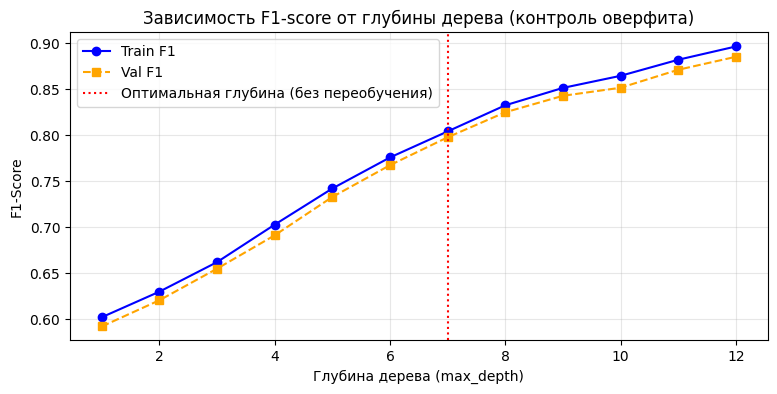

In [35]:
# График обучения и проверка на переобучение
train_scores = []
val_scores = []
depth_range = range(1, 13)

# Прогоняем по разной глубине
for d in depth_range:
  tree = DecisionTreeClassifier(
      max_depth=d, min_samples_split=50, random_state=42
  )
  tree.fit(X_train, y_train)
  train_scores.append(f1_score(y_train, tree.predict(X_train)))
  val_scores.append(f1_score(y_val, tree.predict(X_val)))

# График
plt.figure(figsize=(9, 4))
plt.plot(depth_range, train_scores, label='Train F1', marker='o', color='blue')
plt.plot(
    depth_range, val_scores, label='Val F1', marker='s', color='orange', ls='--'
)
plt.axvline(
    x=7,
    color='red',
    linestyle=':',
    label='Оптимальная глубина (без переобучения)',
)
plt.title('Зависимость F1-score от глубины дерева (контроль оверфита)')
plt.xlabel('Глубина дерева (max_depth)')
plt.ylabel('F1-Score')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Берем ту же глубину, что нашел GridSearch
my_tree = SuperCool1337DecisionTree(
    max_depth=best_sk_tree.max_depth,
    min_samples_split=best_sk_tree.min_samples_split,
)
my_tree.fit(X_train, y_train)
my_tree.fit(X_train, y_train)

In [36]:
# Собираем прогнозы на отложенном Test
base_test_pred = dummy.predict(X_test)
sk_test_pred = best_sk_tree.predict(X_test)
sk_test_prob = best_sk_tree.predict_proba(X_test)[:, 1]

my_test_pred = my_tree.predict(X_test)
my_test_prob = my_tree.predict_proba(X_test)

results_test = pd.DataFrame({
    'Модель': ['Baseline', 'Sklearn DecisionTree', 'SuperCool1337Tree'],
    'Accuracy': [
        accuracy_score(y_test, base_test_pred),
        accuracy_score(y_test, sk_test_pred),
        accuracy_score(y_test, my_test_pred),
    ],
    'F1-Score': [
        f1_score(y_test, base_test_pred, zero_division=0),
        f1_score(y_test, sk_test_pred),
        f1_score(y_test, my_test_pred),
    ],
    'ROC-AUC': [
        0.5,
        roc_auc_score(y_test, sk_test_prob),
        roc_auc_score(y_test, my_test_prob),
    ],
})

results_test.round(4)

,Модель,Accuracy,F1-Score,ROC-AUC
0,Baseline,0.5633,0.7207,0.5000
1,Sklearn DecisionTree,0.9075,0.9177,0.9607
2,SuperCool1337Tree,0.9091,0.9184,0.9614


In [38]:
# Финальная сводная таблица
def calc_metrics(m, X_data, y_data):
  pred = m.predict(X_data)
  if hasattr(m, 'predict_proba'):
    prob = m.predict_proba(X_data)
    if prob.ndim == 2:
      prob = prob[:, 1]
  else:
    prob = pred
  return {
      'Accuracy': accuracy_score(y_data, pred),
      'F1-Score': f1_score(y_data, pred),
      'ROC-AUC': roc_auc_score(y_data, prob),
  }


records = []
for name, model in [
    ('Sklearn Tree', best_sk_tree),
    ('SuperCool1337 Tree', my_tree),
]:
  for split_name, x_s, y_s in [
      ('Train', X_train, y_train),
      ('Val', X_val, y_val),
      ('Test', X_test, y_test),
  ]:
    res = calc_metrics(model, x_s, y_s)
    res.update({'Модель': name, 'Выборка': split_name})
    records.append(res)

df_all = pd.DataFrame(records)[
    ['Модель', 'Выборка', 'Accuracy', 'F1-Score', 'ROC-AUC']
]
display(df_all.round(4))

,Модель,Выборка,Accuracy,F1-Score,ROC-AUC
0,Sklearn Tree,Train,0.9270,0.9348,0.9823
1,Sklearn Tree,Val,0.9049,0.9152,0.9591
2,Sklearn Tree,Test,0.9075,0.9177,0.9607
3,SuperCool1337 Tree,Train,0.9276,0.9349,0.9816
4,SuperCool1337 Tree,Val,0.9097,0.9190,0.9615
5,SuperCool1337 Tree,Test,0.9091,0.9184,0.9614


### Выводы по проделанной работе

1. **Сравнение с baseline-решением:**
* Baseline выдавал случайный уровень качества ($ROC\text{-}AUC = 0.5000$).
* Дерево решений кардинально улучшило качество классификации: $Accuracy \approx 90.9\%$, $F1\text{-}Score \approx 0.918$, $ROC\text{-}AUC \approx 0.961$. Модель успешно нашла ключевые нелинейные зависимости между морфологическими признаками грибов (размеры ножки/шляпки, цвет, сезон) и их токсичностью.


2. **Анализ переобучения (Train vs Val vs Test):**
* Для обеих моделей просадка метрик при переходе с обучающей выборки на отложенный тест минимальна:
* **Sklearn:** Train Accuracy = $0.9270 \rightarrow$ Test Accuracy = $0.9075$ (падение всего на $1.95\%$).
* **Custom Tree:** Train Accuracy = $0.9276 \rightarrow$ Test Accuracy = $0.9091$ (падение всего на $1.85\%$).


* Метрики на валидации и тесте практически не отличаются ($Val \approx 0.909$, $Test \approx 0.909$). Гиперпараметры `max_depth` и `min_samples_split` подобраны корректно: дерево не ушло в оверфит и не зазубрило шум, а выделило реальные паттерны.


3. **Сравнение самописной модели с моделью из фреймворка:**
* Качество самописного дерева `SuperCool1337DecisionTree` и библиотечного `DecisionTreeClassifier` из совпало практически один в один на всех срезах данных:
* На тесте по **Accuracy:** $0.9075$ (Sklearn) против $0.9091$ (SuperCool1337) — расхождение $0.16\%$.
* На тесте по **F1-Score:** $0.9177$ (Sklearn) против $0.9184$ (SuperCool1337) — расхождение менее $0.001$.
* На тесте по **ROC-AUC:** $0.9607$ (Sklearn) против $0.9614$ (SuperCool1337) — расхождение менее $0.001$.


* Такое совпадение подтверждает, что математический аппарат (расчет неопределенности Джини, жадный выбор лучшего сплита по квантилям и рекурсивное построение узлов) реализован корректно.